# Agente LangGraph con búsqueda web, optimizado en coste

La búsqueda web es cara: los tokens que devuelve Tavily se cobran como `input_tokens`.
Este notebook usa `agent_search_pro.py` del paquete `mario_mendoza_langgraph_websearchagent` y cubre tres cosas:

1. **System prompt** que usa conocimiento propio para lo anterior a julio 2025 y busca solo si hace falta.
2. **Tokens**: totales y los que suponen los resultados de la herramienta.
3. **Tool messages** impresos de forma legible.

In [2]:
from langchain.messages import HumanMessage
import pandas as pd
import sys

sys.path.insert(
    0,
    r"C:\Users\mario\Desktop\DC Academy\IA Automation\LangGraph\mario-mendoza-langgraph-websearchagent\src",
)

from mario_mendoza_langgraph_websearchagent.agent_search_pro import (
    create_agent,
    run_agent,
    get_token_usage,
    print_token_usage,
    print_tool_messages,
    build_system_prompt,
)

## 1. Crear el agente
Si faltan las API keys (`.env`), te las pide.

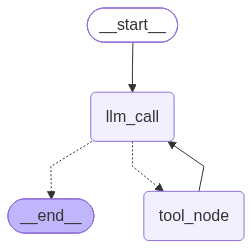

In [3]:
agent = create_agent()

# Opcional: dibujar el grafo
from IPython.display import Image, display
display(Image(agent.get_graph(xray=True).draw_mermaid_png()))

## 2. System prompt
Este es el prompt que decide cuándo buscar:

In [4]:
print(build_system_prompt(use_search=True))

You are an expert on LangChain and LangGraph and a helpful general assistant.
Today's date is 2026-10-20. Your training knowledge ends in July 2025.
Always answer in the same language as the user's question.

Web searches are expensive, so first decide whether you really need one.

Answer directly from your own knowledge, WITHOUT searching, when the question is about:
- Stable knowledge from before July 2025: concepts, definitions, history, science, math, and how established libraries and APIs work.
- Writing or explaining code, text or reasoning that needs no external data.
- Simple arithmetic (use the multiply tool for multiplications).

Use the search tool ONLY when:
- The question is about events, releases or versions after July 2025, or about data that changes over time (news, prices, weather, 'latest', 'current', 'today').
- You do not know the answer, or you are not confident your knowledge is up to date.

When you search: make ONE focused search with a short query. Search again

## 3. Una consulta de ejemplo
`run_agent` imprime la conversación, los tool messages (si hay) y el resumen de tokens.

In [5]:
result = run_agent(agent, "¿Cuál es la última versión estable de LangChain?")

================================ Human Message =================================

¿Cuál es la última versión estable de LangChain?
================================== Ai Message ==================================

[{'text': 'Voy a buscar la información sobre la última versión estable de LangChain, ya que mi conocimiento se detiene en julio de 2025 y es importante tener datos actualizados sobre las versiones.', 'type': 'text'}, {'id': 'toolu_01PzKiE9wMxLinS1458Qf2zz', 'caller': {'type': 'direct'}, 'input': {'query': 'LangChain latest stable version 2026', 'search_depth': 'basic'}, 'name': 'tavily_search', 'type': 'tool_use', 'toolset_name': None}]
Tool Calls:
  tavily_search (toolu_01PzKiE9wMxLinS1458Qf2zz)
 Call ID: toolu_01PzKiE9wMxLinS1458Qf2zz
  Args:
    query: LangChain latest stable version 2026
    search_depth: basic
TOOL MESSAGE 1: tavily_search (7626 chars)
Query:         LangChain latest stable version 2026
Results:       5
Response time: 1.19 s

[1] Udemy Free Courses | 100%

## 4. Batería de pruebas

Cada query tiene un comportamiento esperado:

- **sin búsqueda**: conocimiento estable anterior a julio 2025 (o aritmética con la tool `multiply`).
- **búsqueda**: información posterior a julio 2025 o que cambia con el tiempo.
- **dudoso**: existía antes del corte, pero ha cambiado después. Aquí se decide mirando la comparación con el agente sin búsqueda (sección 7).

In [6]:
tests = [
    # Conocimiento estable -> NO debería buscar
    {"query": "¿Qué es un conditional edge en LangGraph y para qué sirve?", "expected": "sin búsqueda"},
    {"query": "¿Cuál es la capital de Australia?", "expected": "sin búsqueda"},
    {"query": "Escribe una función en Python que compruebe si una palabra es un palíndromo.", "expected": "sin búsqueda"},
    {"query": "Multiplica 1234 por 5678.", "expected": "sin búsqueda"},

    # Información actual o posterior al corte -> debería buscar
    {"query": "¿Cuál es la última versión estable de LangChain?", "expected": "búsqueda"},
    {"query": "¿Qué novedades trae LangChain 1.0 respecto a la 0.3?", "expected": "búsqueda"},
    {"query": "¿Cuál es la última versión de Python disponible?", "expected": "búsqueda"},
    {"query": "¿Cuál es el precio actual de Bitcoin en euros?", "expected": "búsqueda"},
    {"query": "¿Qué modelos de Claude hay disponibles actualmente en la API?", "expected": "búsqueda"},

    # Casos dudosos
    {"query": "¿Qué es el Model Context Protocol (MCP)?", "expected": "dudoso"},
    {"query": "¿Cómo se crea un agente ReAct con create_react_agent en LangGraph?", "expected": "dudoso"},
]

In [7]:
def run_test_suite(agent, tests):
    """Ejecuta todas las queries y devuelve (tabla resumen, lista de resultados del grafo)."""
    rows = []
    results = []

    for test in tests:
        result = agent.invoke({"messages": [HumanMessage(content=test["query"])]})
        usage = get_token_usage(result["messages"])
        searched = usage["search_calls"] > 0

        if test["expected"] == "dudoso":
            correct = "revisar"
        elif (test["expected"] == "búsqueda") == searched:
            correct = "sí"
        else:
            correct = "NO"

        rows.append({
            "query": test["query"],
            "esperado": test["expected"],
            "buscó": searched,
            "decisión correcta": correct,
            "búsquedas": usage["search_calls"],
            "total tokens": usage["total_tokens"],
            "tokens tool": usage["tool_result_tokens"],
        })
        results.append(result)

    return pd.DataFrame(rows), results

In [8]:
df, results = run_test_suite(agent, tests)

pd.set_option("display.max_colwidth", 60)
df

,query,esperado,buscó,decisión correcta,búsquedas,total tokens,tokens tool
0,¿Qué es un conditional edge en LangGraph y para qué sirve?,sin búsqueda,False,sí,0,3278,0
1,¿Cuál es la capital de Australia?,sin búsqueda,False,sí,0,2642,0
2,Escribe una función en Python que compruebe si una palab...,sin búsqueda,False,sí,0,3185,0
3,Multiplica 1234 por 5678.,sin búsqueda,False,sí,0,5300,15
4,¿Cuál es la última versión estable de LangChain?,búsqueda,True,sí,2,18532,6341
5,¿Qué novedades trae LangChain 1.0 respecto a la 0.3?,búsqueda,True,sí,1,7896,1813
6,¿Cuál es la última versión de Python disponible?,búsqueda,True,sí,2,13030,3736
7,¿Cuál es el precio actual de Bitcoin en euros?,búsqueda,True,sí,1,8763,3228
8,¿Qué modelos de Claude hay disponibles actualmente en la...,búsqueda,True,sí,1,8986,3170
9,¿Qué es el Model Context Protocol (MCP)?,dudoso,False,revisar,0,3020,0


In [9]:
print(f"Tokens totales de la batería:      {df['total tokens'].sum()}")
print(f"Tokens de resultados de búsqueda:  {df['tokens tool'].sum()}")
print(f"Decisiones incorrectas:            {(df['decisión correcta'] == 'NO').sum()}")
print()
print("Tokens medios por tipo de decisión:")
print(df.groupby("buscó")["total tokens"].mean().round(0))

Tokens totales de la batería:      78122
Tokens de resultados de búsqueda:  18303
Decisiones incorrectas:            0

Tokens medios por tipo de decisión:
buscó
False     3486.0
True     11441.0
Name: total tokens, dtype: float64


## 5. Inspeccionar los tool messages
`print_tool_messages` muestra query, tiempo de respuesta y, para cada resultado de Tavily, título, URL, score y contenido (recortado a `max_chars`; usa `max_chars=None` para verlo completo).

In [10]:
# Primera ejecución de la batería que sí usó búsqueda
index = df.index[df["buscó"]][0]
print("Query:", df.loc[index, "query"], "\n")

print_tool_messages(results[index]["messages"], max_chars=300)

Query: ¿Cuál es la última versión estable de LangChain? 

TOOL MESSAGE 1: tavily_search (7625 chars)
Query:         LangChain latest stable version 2026
Results:       5
Response time: 0.0 s

[1] Udemy Free Courses | 100% OFF Udemy Coupon codes 2026 | Course Coupon ...
    URL:     https://t.me/s/coursecouponclub?q=#AIagents&before=55526
    Score:   0.37648612
    Content (1022 chars): Udemy Coupon Code For OpenClaw Agents, LangChain , HuggingFace, LLM & Gen AI, Find Out Other Highest rated and Bestselling Generative AI & LLM & AI Agents' Courses with... Dein Recht auf Meinungsfreiheit. Mehr auf www.HAINTZ.media Impressum: HAINTZ.media GmbH c/o Trevisca AG Zugerstrasse 74 6340 Baa... [+722 chars]

[2] TheSanskaarSingh – Telegram
    URL:     https://t.me/s/codeslearningTG?before=1535
    Score:   0.19475074
    Content (1327 chars): TheSanskaarSingh 7 websites that actually give you remote work in 2026 👇 1/ Remote OK: 2/ We Work Remotely: 3/ Himalayas: 4/ Jobspresso: 5/ Dynamite Jobs:

In [11]:
# Mismo mensaje, sin recortar el contenido
print_tool_messages(results[index]["messages"], max_chars=None)

TOOL MESSAGE 1: tavily_search (7625 chars)
Query:         LangChain latest stable version 2026
Results:       5
Response time: 0.0 s

[1] Udemy Free Courses | 100% OFF Udemy Coupon codes 2026 | Course Coupon ...
    URL:     https://t.me/s/coursecouponclub?q=#AIagents&before=55526
    Score:   0.37648612
    Content (1022 chars): Udemy Coupon Code For OpenClaw Agents, LangChain , HuggingFace, LLM & Gen AI, Find Out Other Highest rated and Bestselling Generative AI & LLM & AI Agents' Courses with... Dein Recht auf Meinungsfreiheit. Mehr auf www.HAINTZ.media Impressum: HAINTZ.media GmbH c/o Trevisca AG Zugerstrasse 74 6340 Baar Schweiz kontakt@haintz.media IBAN: BE64... What you will learn? This is a complete beginner-friendly AI Fundamentals tutorial which will teach you about LLMs, Transformers, Embeddings, Vector Store, RAG, AI... I work to bring AI into production. I write about AI system design. 92 views21:45 Data Engineering https://www. langchain .com/blog/the-anatomy-of-an-agent-

## 6. Tokens de una ejecución concreta
`get_token_usage` devuelve un diccionario (útil para guardar o comparar), `print_token_usage` lo imprime.

In [12]:
usage = get_token_usage(results[index]["messages"])
usage

{'llm_calls': 3,
 'search_calls': 2,
 'input_tokens': 17947,
 'output_tokens': 585,
 'total_tokens': 18532,
 'tool_result_tokens': 6341,
 'tool_input_tokens_billed': 9864,
 'tool_share_of_input': 55.0}

## 7. ¿Estaba justificada la búsqueda? Comparar con el agente sin búsqueda
Se crea el mismo agente sin la herramienta de búsqueda (`use_search=False`; su prompt le indica que avise si no está seguro) y se comparan respuesta y tokens.

In [13]:
agent_no_search = create_agent(use_search=False)


def answer_text(message):
    """Devuelve el texto de un mensaje (el contenido puede ser texto o una lista de bloques)."""
    if isinstance(message.content, str):
        return message.content
    return "".join(block.get("text", "") for block in message.content if isinstance(block, dict))


def compare_with_and_without_search(query):
    with_search = agent.invoke({"messages": [HumanMessage(content=query)]})
    without_search = agent_no_search.invoke({"messages": [HumanMessage(content=query)]})

    for title, result in [("CON búsqueda", with_search), ("SIN búsqueda", without_search)]:
        usage = get_token_usage(result["messages"])
        print("=" * 70)
        print(f"{title} | búsquedas: {usage['search_calls']} | tokens totales: {usage['total_tokens']}")
        print("=" * 70)
        print(answer_text(result["messages"][-1]))
        print()

In [14]:
dudosos = [t["query"] for t in tests if t["expected"] == "dudoso"]

for query in dudosos:
    print("#" * 70)
    print("QUERY:", query)
    print("#" * 70)
    compare_with_and_without_search(query)

######################################################################
QUERY: ¿Qué es el Model Context Protocol (MCP)?
######################################################################
CON búsqueda | búsquedas: 0 | tokens totales: 3020
El **Model Context Protocol (MCP)** es un protocolo abierto desarrollado por Anthropic que permite que las aplicaciones cliente se conecten con servidores que proporcionan contexto, herramientas y datos a modelos de lenguaje.

## Características principales:

**Propósito:**
- Estandarizar la forma en que los modelos de IA acceden a información externa, herramientas y recursos
- Facilitar la integración de fuentes de datos y capacidades sin modificar el modelo base

**Componentes clave:**
- **Servidores MCP**: Proporcionan recursos como herramientas, datos, archivos o conexiones a sistemas externos
- **Clientes MCP**: Aplicaciones que se conectan a los servidores para obtener contexto y ejecutar herramientas
- **Protocolo de comunicación**: Define có